In [6]:
import librosa 
path="old.mp3" 
y,sr=librosa.load(path,sr=None,mono=False)
print("Sample rate",sr,"hz")
print("Duration",len(y)/sr)
print('Number of samples ',len(y))
print("shape",y.shape)





Sample rate 44100 hz
Duration 4.5351473922902495e-05
Number of samples  2
shape (2, 16602180)


IndexError: index -1 is out of bounds for axis 0 with size 0

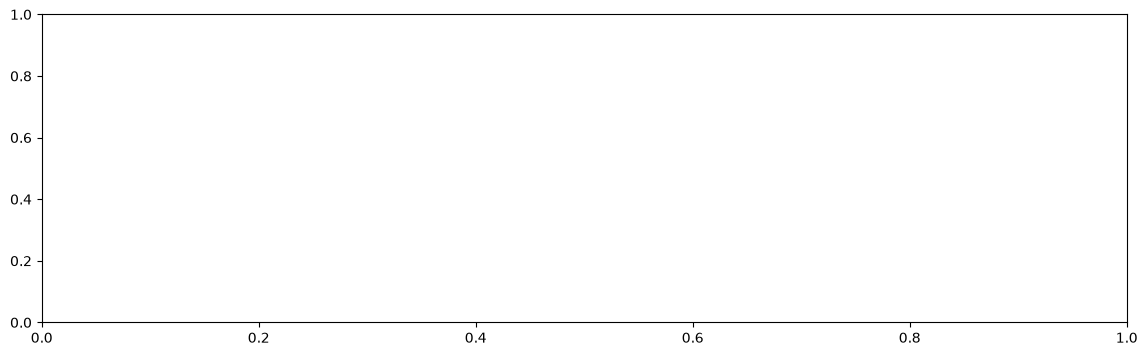

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.figure(figsize=(14,4))
librosa.display.waveshow(y[60*sr:70*sr],sr=sr)
plt.title('WAVEFORM')
plt.xlabel('time')
plt.ylabel('amplitude')
plt.show()
print(np.abs(y).max(),np.abs(y).min(),np.abs(y).mean())

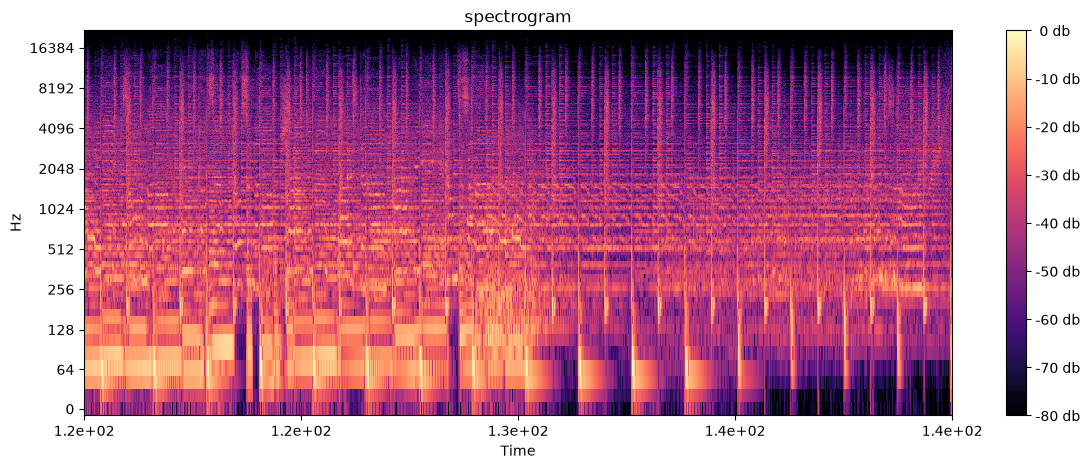

In [4]:
#SPECTROGRAM
d=librosa.stft(y)
#STFT
#convert amplitude into decibels
db=librosa.amplitude_to_db(np.abs(d),ref=np.max)
plt.figure(figsize=(14,5))
librosa.display.specshow(db,sr=sr,y_axis='log',x_axis='time')
plt.colorbar(format='%2.0f db')
plt.xlim(120,140)
plt.title('spectrogram')
plt.show()


In [ ]:
from scipy.signal import butter, sosfilt

def bandpass(y, sr, low, high):
    sos = butter(4, [low, high], btype='band', fs=sr, output='sos')
    return sosfilt(sos, y)

# test your bass hypothesis
bass_guess = bandpass(y, sr, 40, 150)
# save it and listen
import soundfile as sf
sf.write("bass_guess.wav", bass_guess, sr)
#vibecoded


In [7]:
import soundfile as sf 
import numpy as np
right=y[1]
left=y[0]
instrumental=right-left
sf.write("Phase_cancel_puma.wav",instrumental,sr)
